<a href="https://colab.research.google.com/github/menneli/PDA-1/blob/Lab_3/%D0%9B%D0%A03_%D0%9E%D0%B1%D0%B5%D1%81%D0%BF%D0%B5%D1%87%D0%B5%D0%BD%D0%B8%D0%B5_%D0%BA%D0%B0%D1%87%D0%B5%D1%81%D1%82%D0%B2%D0%B0_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [ ]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns

В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/lab3/monster_com_job_sample.csv'

df = pd.read_csv(DATA_PATH)
print('Размер датасета (строки, столбцы):', df.shape)

with pd.option_context('display.max_colwidth', 60, 'display.max_columns', None):
    display(df.sample(5, random_state=42))

df.info()

for col in df.columns:
    vals = df[col].dropna().astype(str)
    sample = vals.sample(min(3, len(vals)), random_state=1).str.slice(0, 80).tolist()
    print(f'{col:16s}', sample)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Размер датасета (строки, столбцы): (22000, 14)


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding of food s...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lead-Job-Sant...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Sunset-Point...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation PR will b...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundation-pr-job-...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Groundskeeper. D...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-Knoxville-T...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,Combined Insurance is seeking Sales Agents to join our f...,Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Knoxville-TN-...,NaN,NaN,ec59e3f419b851259632b757183d7365


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   country          22000 non-null  object
 1   country_code     22000 non-null  object
 2   date_added       122 non-null    object
 3   has_expired      22000 non-null  object
 4   job_board        22000 non-null  object
 5   job_description  22000 non-null  object
 6   job_title        22000 non-null  object
 7   job_type         20372 non-null  object
 8   location         22000 non-null  object
 9   organization     15133 non-null  object
 10  page_url         22000 non-null  object
 11  salary           3446 non-null   object
 12  sector           16806 non-null  object
 13  uniq_id          22000 non-null  object
dtypes: object(14)
memory usage: 2.3+ MB
country          ['United States of America', 'United States of America', 'United States of America']
country_code     ['US', 'US'

**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.


Название столбца | Тип данных | Проблемы
--- | --- | ---
```country``` | `object` | Во всех строках одно значение (`United States of America`) - константа, дублирует `country_code`
```country_code``` | `object` | Константа (`US`), избыточна вместе с `country`
```date_added``` | `object` | Заполнен всего в 122 строках из 22 000, даты записаны строкой в формате `M/D/YYYY`, не `datetime`
```has_expired``` | `object` | Константа (`No`), бинарный признак хранится строкой
```job_board``` | `object` | Константа (`jobs.monster.com`), довольно бесполезно
```job_description``` | `object` | Служебные символы, пункты и абзацы слиплись без разделителей, служебные хвосты (`Apply Here`, номера вакансий, CSS)
```job_title``` | `object`  | У 18 855 строк приписка `Job in <город>`; в ~1 100 названий попал CSS-мусор (`body { margin:px; ...`); местоположение смешано с должностью
```job_type``` | `object` | 39 вариантов записи одного и того же (`Full Time Employee`, `Full Time, Employee`, `Full Time / Employee`…); смешаны «полнота» и «тип» занятости, префикс `Job Type`; пропуски
```location``` | `object`  | Форматы «город, штат, индекс» в разных сочетаниях; ~1 260 значений - это уже текст вакансии, плюс `Location:` без данных, `Contact name ...`/`Phone ...`, названия должностей
```organization``` | `object` | 31% пропусков; по факту хранит отрасль (`Healthcare Services`, `Retail`), а не название организации; есть склеенные значения и длинные тексты; 126 значений совпадают со значениями `location`
```page_url``` | `object`  | Все значения различны; содержит технические параметры (`mescoid`, `jobPosition`); город и должность включены в URL
```salary``` | `object`  | Много пропусков (есть только ~3500 из 22000 записей) форматы разные (диапазон, `70,000.00+`, с `$` и без), период иногда отсутствует, текст приписан слитно (`/yearProfit Sharing`)
```sector``` | `object`  | Почти четверть пропусков; по факту содержит уровень/категорию позиции (`Experienced (Non-Manager)`, `Entry Level`), есть склеенные значения и отдельные длинные тексты
```uniq_id``` | `object` | Уникален во всех 22 000 строках, но 2 078 строк - дубликаты по остальным столбцам (кроме `page_url`): одна вакансия под разными `uniq_id`


### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью столбчатой диаграммы. Для удобства можно воспользоваться модулем `missingno`.


,total_cells,empty_cells,empty_pct
date_added,22000,21878,99.45
salary,22000,18557,84.35
organization,22000,6867,31.21
sector,22000,5194,23.61
job_type,22000,1628,7.40
country,22000,0,0.00
job_description,22000,0,0.00
job_board,22000,0,0.00
has_expired,22000,0,0.00
country_code,22000,0,0.00


Строк, где пусто более 75% ячеек: 0 из 22000


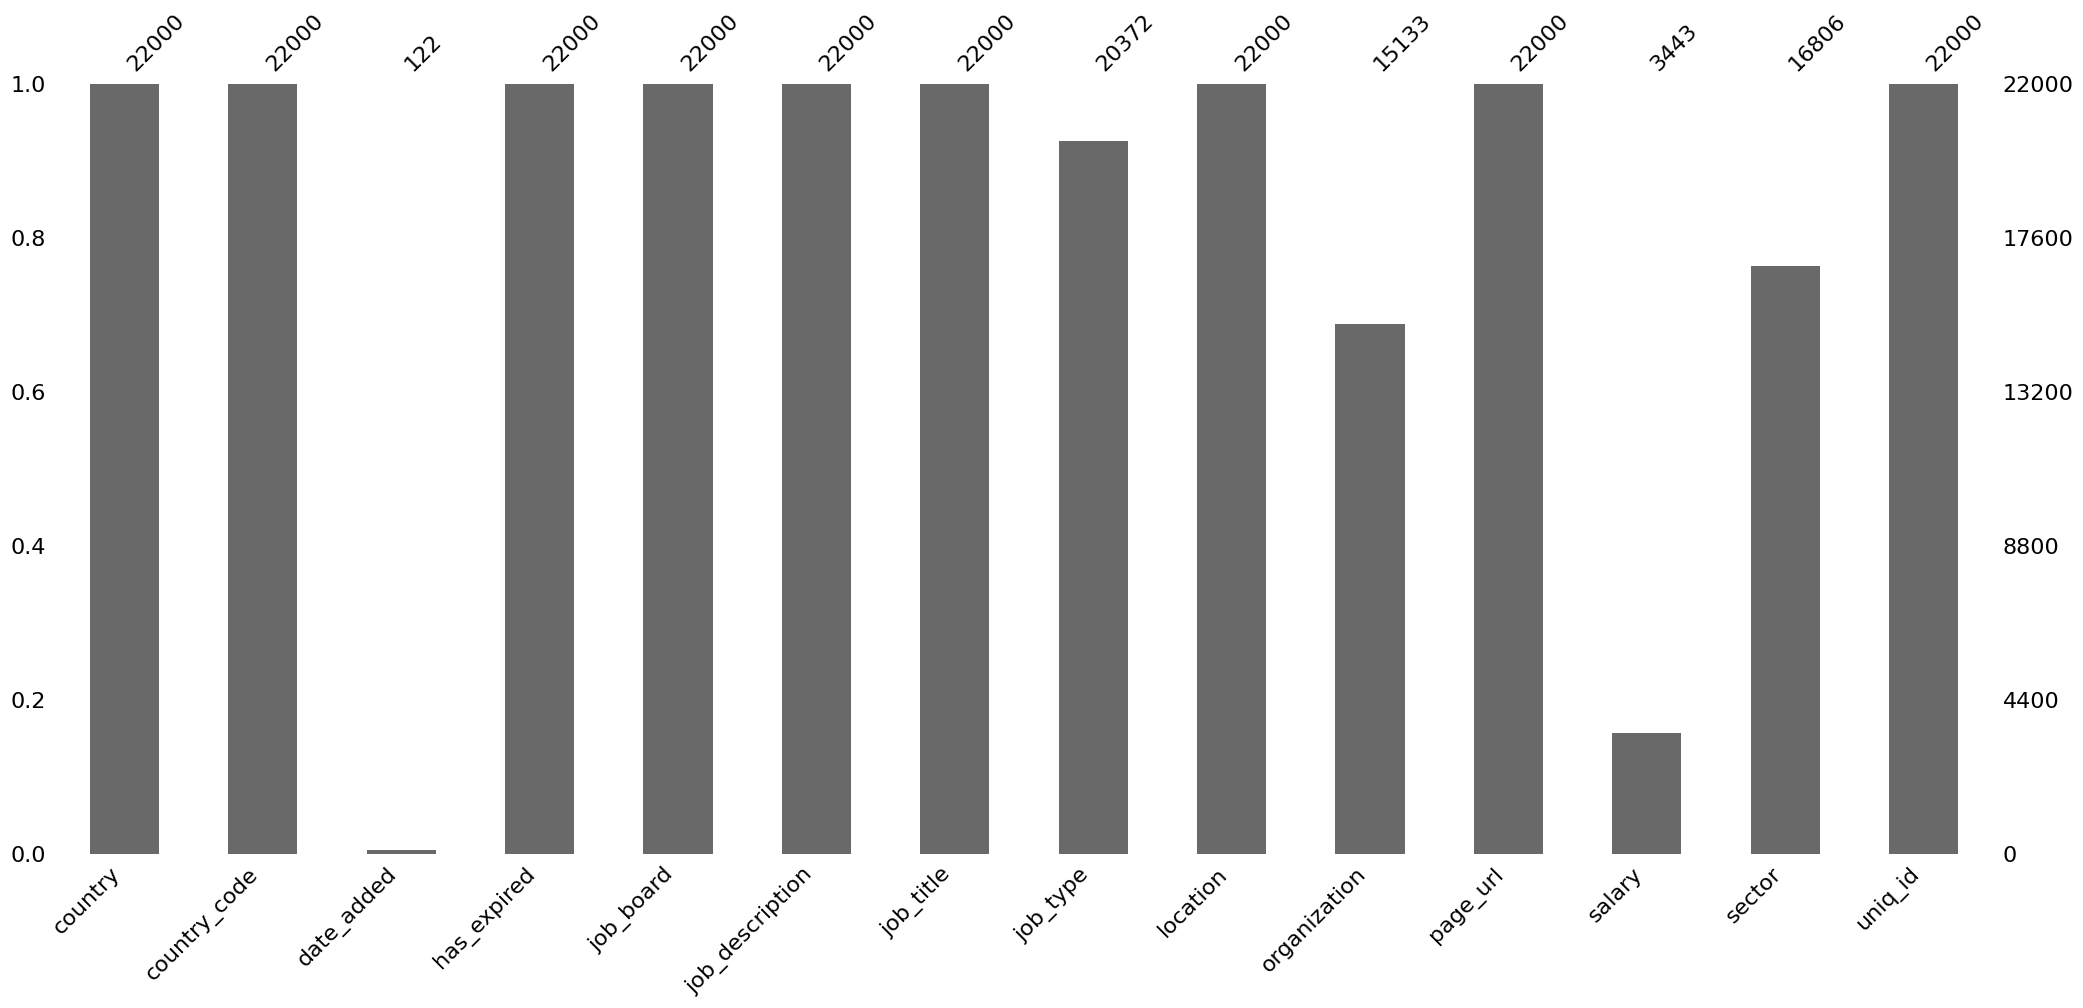

In [ ]:
# пустыми считаем NaN, строки, состоящие только из пробелов
df_na = df.replace(r'^\s*$', np.nan, regex=True)

missing = pd.DataFrame({
    'total_cells': len(df_na),
    'empty_cells': df_na.isna().sum(),
})
missing['empty_pct'] = (missing['empty_cells'] / missing['total_cells'] * 100).round(2)
display(missing.sort_values('empty_cells', ascending=False))

row_empty_share = df_na.isna().mean(axis=1)
n_sparse_rows = (row_empty_share > 0.75).sum()
print(f'Строк, где пусто более 75% ячеек: {n_sparse_rows} из {len(df_na)}')

msno.bar(df_na)
plt.show()

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [ ]:
print('Исходный размер:           ', df_na.shape)
print('После dropna() по всем столбцам:', df_na.dropna().shape)

Исходный размер:            (22000, 14)
После dropna() по всем столбцам: (5, 14)


**Выводы**

- Пропуски: `date_added` - 99,45%, `salary` - 84,35%, `organization` - 31,21%, `sector` - 23,61%, `job_type` - 7,4%; строк, где пусто >75% ячеек, нет.
- `dropna()` оставляет **5 строк из 22 000**; даже без `date_added` - 1 918. Удалять строки с пропусками нельзя: данных не останется. Лучше не использовать почти пустые столбцы (`date_added`) и обрабатывать остальные по отдельности (`salary` пуст у большинства вакансий - это нормальная ситуация, а не ошибка).

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [ ]:
n_unique = df_na.nunique(dropna=True)
print('Число уникальных значений по столбцам:')
print(n_unique.sort_values())

const_cols = n_unique[n_unique == 1].index.tolist()
print('\nКонстантные столбцы:')
for c in const_cols:
    print(f'  {c!r}: значение = {df_na[c].dropna().iloc[0]!r}, пустых ячеек = {df_na[c].isna().sum()}')

# значения, которые встречаются более чем в одном столбце
from itertools import combinations

skip = {'job_description', 'page_url', 'uniq_id'}
cols = [c for c in df_na.columns if c not in skip]
value_sets = {c: set(df_na[c].dropna().astype(str).str.strip().str.lower()) for c in cols}

rows = []
for a, b in combinations(cols, 2):
    common = value_sets[a] & value_sets[b]
    if common:
        rows.append({'col_1': a, 'col_2': b, 'n_common': len(common),
                     'examples': sorted(common)[:5]})
overlap = pd.DataFrame(rows).sort_values('n_common', ascending=False) if rows else pd.DataFrame()
print('\nПары столбцов с общими значениями:')
display(overlap)

# столбцы, данные в которых не соответствуют названию
def share(mask):
    return int(mask.sum())

checks = {
    'country_code не из двух заглавных букв':
        df_na['country_code'].notna() & ~df_na['country_code'].astype(str).str.fullmatch(r'[A-Z]{2}'),
    'has_expired не Yes/No':
        df_na['has_expired'].notna() & ~df_na['has_expired'].isin(['Yes', 'No']),
    'date_added не парсится как дата':
        df_na['date_added'].notna() & pd.to_datetime(df_na['date_added'], errors='coerce').isna(),
    'salary без единой цифры':
        df_na['salary'].notna() & ~df_na['salary'].astype(str).str.contains(r'\d'),
    'location без цифр и без запятой (не похоже на адрес)':
        df_na['location'].notna() & ~df_na['location'].astype(str).str.contains(r'[\d,]'),
    'organization есть в списке sector':
        df_na['organization'].str.strip().str.lower().isin(value_sets['sector']),
    'sector есть в списке organization':
        df_na['sector'].str.strip().str.lower().isin(value_sets['organization']),
    'job_type очень длинный (>40 симв.)':
        df_na['job_type'].astype(str).str.len().gt(40) & df_na['job_type'].notna(),
}

for c in ['job_title', 'job_type', 'location', 'organization', 'salary', 'sector']:
    checks[f'{c}: текст длиннее 150 символов'] = df_na[c].astype(str).str.len().gt(150) & df_na[c].notna()

report = pd.Series({k: share(v) for k, v in checks.items()}, name='n_rows')
display(report.to_frame())

for name, mask in checks.items():
    if mask.sum():
        col = name.split(' ')[0].split(':')[0]
        col = col if col in df_na.columns else None
        print(f'\n{name}  ->  {int(mask.sum())} строк')
        if col:
            print(df_na.loc[mask, col].astype(str).str.slice(0, 100).head(5).tolist())

Число уникальных значений по столбцам:
country                1
country_code           1
has_expired            1
job_board              1
job_type              39
date_added            78
sector               163
organization         738
salary              1736
location            8423
job_description    18744
job_title          18759
page_url           22000
uniq_id            22000
dtype: int64

Константные столбцы:
  'country': значение = 'United States of America', пустых ячеек = 0
  'country_code': значение = 'US', пустых ячеек = 0
  'has_expired': значение = 'No', пустых ячеек = 0
  'job_board': значение = 'jobs.monster.com', пустых ячеек = 0

Пары столбцов с общими значениями:


,col_1,col_2,n_common,examples
3,location,organization,126,"[a & e network, albany, ny, allentown, pa, app..."
0,job_title,location,12,"[business analyst, field service technician, j..."
4,organization,sector,2,[electrical/electronics engineeringindustrial/...
2,job_type,organization,1,[full time employee]
1,job_type,location,1,[full time employee]


,n_rows
country_code не из двух заглавных букв,0
has_expired не Yes/No,0
date_added не парсится как дата,0
salary без единой цифры,358
location без цифр и без запятой (не похоже на адрес),1200
organization есть в списке sector,1082
sector есть в списке organization,24
job_type очень длинный (>40 симв.),2
job_title: текст длиннее 150 символов,99
job_type: текст длиннее 150 символов,0



salary без единой цифры  ->  358 строк
['Excellent Pay and Incentives', 'Salary, plus commission', 'To be discussed.', 'DOE', 'Negotiable based on experience']

location без цифр и без запятой (не похоже на адрес)  ->  1200 строк
['Contact name Tony Zerio', 'Bi-Lingual Editorial Strategist', 'Quality Engineer', 'Telecommute', 'Business Analyst']

organization есть в списке sector  ->  1082 строк
['Retail', 'Retail', 'Retail', 'Retail', 'Retail']

sector есть в списке organization  ->  24 строк
['Retail', 'Retail', 'Retail', 'Electrical/Electronics EngineeringIndustrial/Manufacturing EngineeringMechanical Engineering', 'Retail']

job_type очень длинный (>40 симв.)  ->  2 строк
['Job Type Full Time Temporary/Contract/Project', 'Job Type Full Time Temporary/Contract/Project']

job_title: текст длиннее 150 символов  ->  99 строк
['Combat Engineer - Construction and Engineering Specialist Job in La Porte  body { margin:px; overflo', 'Combat Engineer - Construction and Engineering Specialis

**Ответы**
1. Одно значение: `country`, `country_code`, `has_expired`, `job_board`. Для анализа они бесполезны (константа не различает объекты) - их можно удалить.
2. Общие значения в разных столбцах: `location` и `organization` (126 значений - в `organization` попадают адреса, например `Dallas, TX`), `job_title` и `location` (12 - названия должностей в `location`), `job_type` встречается в `location` и `organization` (`Full Time Employee`), `organization` и `sector` (2).
3. Не соответствуют названию: `location` (~1 260 значений длиннее 100 символов - текст вакансии; также `Location:`, `Phone ...`, `Contact name ...`, должности); `organization` (хранит отрасль, а не организацию; ~660 длинных значений); `sector` (хранит уровень позиции); `job_title` (CSS у ~1 100); `salary` (358 значений без цифр, 10 с длинным текстом).

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [ ]:
print('Всего строк:             ', len(df))
print('Уникальных uniq_id:      ', df['uniq_id'].nunique(dropna=False))
print('uniq_id действительно уникален:', df['uniq_id'].is_unique)
dup_ids = df['uniq_id'].duplicated(keep=False)
print('Строк с повторяющимся uniq_id:', dup_ids.sum())
if dup_ids.sum():
    display(df[dup_ids].sort_values('uniq_id').head(10))

# жругие столбцы, где все значения различны
all_distinct = [c for c in df.columns if df[c].nunique(dropna=False) == len(df)]
print('\nСтолбцы, где все значения различны:', all_distinct)

# дубликаты по всем остальным столбцам
other_cols = [c for c in df.columns if c not in all_distinct]
dup_mask = df.duplicated(subset=other_cols, keep=False)
print(f'\nСтрок-дубликатов (все остальные столбцы совпадают): {dup_mask.sum()}')
print('Размер датасета после drop_duplicates:', df.drop_duplicates(subset=other_cols).shape)

if dup_mask.sum():
    dups = df[dup_mask].sort_values(other_cols)
    with pd.option_context('display.max_colwidth', 40):
        display(dups.head(10))

    # размеры групп дубликатов
    group_sizes = dups.groupby(other_cols, dropna=False).size()
    print('\nРаспределение размеров групп дубликатов:')
    print(group_sizes.value_counts().sort_index())

Всего строк:              22000
Уникальных uniq_id:       22000
uniq_id действительно уникален: True
Строк с повторяющимся uniq_id: 0

Столбцы, где все значения различны: ['page_url', 'uniq_id']

Строк-дубликатов (все остальные столбцы совпадают): 2078
Размер датасета после drop_duplicates: (20832, 14)


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
15246,United States of America,US,10/27/2016,No,jobs.monster.com,"#TrackingJobBody table, #TrackingJob...",Field Laborer (No Experience Require...,Full Time Employee,"Cannon Falls, MN",Other/Not Classified,http://jobview.monster.com/field-lab...,NaN,Manufacturing/Production/Operations,8cb9869a204ecbd33e4c8abf97a05e55
15562,United States of America,US,10/27/2016,No,jobs.monster.com,"#TrackingJobBody table, #TrackingJob...",Field Laborer (No Experience Require...,Full Time Employee,"Cannon Falls, MN",Other/Not Classified,http://jobview.monster.com/field-lab...,NaN,Manufacturing/Production/Operations,4d3052d304a5df1e6439f895927cd165
4720,United States of America,US,9/22/2016,No,jobs.monster.com,Job Description The Corporate Fit F...,Corporate Fit For Duty Program Manag...,Full Time Employee,"Norwell, MA",Other/Not Classified,http://jobview.monster.com/corporate...,NaN,Project/Program Management,d2428de246bb737929ac1789037075c0
10527,United States of America,US,9/22/2016,No,jobs.monster.com,Job Description The Corporate Fit F...,Corporate Fit For Duty Program Manag...,Full Time Employee,"Norwell, MA",Other/Not Classified,http://jobview.monster.com/corporate...,NaN,Project/Program Management,501d214d1179f3a918133aa82ac1adfa
4718,United States of America,US,9/22/2016,No,jobs.monster.com,Resource Management Program Analyst-...,Resource Management Program Analyst ...,"Full Time, Employee","Alexandria, VA",Computer Software,http://jobview.monster.com/resource-...,NaN,Project/Program Management,57e12199f939f374ea1885c37dd04276
10645,United States of America,US,9/22/2016,No,jobs.monster.com,Resource Management Program Analyst-...,Resource Management Program Analyst ...,"Full Time, Employee","Alexandria, VA",Computer Software,http://jobview.monster.com/resource-...,NaN,Project/Program Management,cb6dc45b67bb36535576a06a76ce4c46
2116,United States of America,US,NaN,No,jobs.monster.com,"""HOUSTON'S FIRST""A New Era in the Li...",Registered Nurse (RN) - Traveler - ...,Full Time Employee,"Houston, TX 77001",NaN,http://jobview.monster.com/registere...,NaN,Medical/Health,124575a96e019163c2e2446f35e51390
20303,United States of America,US,NaN,No,jobs.monster.com,"""HOUSTON'S FIRST""A New Era in the Li...",Registered Nurse (RN) - Traveler - ...,Full Time Employee,"Houston, TX 77001",NaN,http://jobview.monster.com/registere...,NaN,Medical/Health,b3c2709e899075818725ff20aee7608f
4221,United States of America,US,NaN,No,jobs.monster.com,"""We are looking for enthusiastic, ca...",Entry Level Insurance Sales Job in S...,Full Time,"San Marcos, CA 92078",Insurance,http://jobview.monster.com/entry-lev...,NaN,Customer Support/Client Care,d75b281e267e9442fda072da20a95518
21142,United States of America,US,NaN,No,jobs.monster.com,"""We are looking for enthusiastic, ca...",Entry Level Insurance Sales Job in S...,Full Time,"San Marcos, CA 92078",Insurance,http://jobview.monster.com/entry-lev...,NaN,Customer Support/Client Care,bb794a8c2cb50fb67cf64ed319928924



Распределение размеров групп дубликатов:
2     809
3      61
4      16
5       8
6       5
7       2
9       1
10      1
11      2
13      2
16      1
22      1
24      1
Name: count, dtype: int64


**Оценка**
- `uniq_id` уникален (22 000 различных значений); кроме него все значения различны только в `page_url`.
- Если игнорировать эти два столбца, 2 078 строк - дубликаты (группы по 2-24 записи; после `drop_duplicates` остаётся 20 832 строки). Это одни и те же вакансии, опубликованные несколько раз с разными `uniq_id`/`page_url`; для анализа лучше оставить по одной записи из группы.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

In [ ]:
import itertools

US_STATE_NAMES = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH',
    'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC',
    'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
    'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD', 'Tennessee': 'TN',
    'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA',
    'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY', 'District of Columbia': 'DC',
}
EXTRA_CODES = {'PR', 'GU', 'VI', 'AS', 'MP',
               'AB', 'BC', 'MB', 'NB', 'NL', 'NS', 'NT', 'NU', 'ON', 'PE', 'QC', 'SK', 'YT'}
STATE_CODES = set(US_STATE_NAMES.values()) | EXTRA_CODES
NAME_TO_CODE = {k.lower(): v for k, v in US_STATE_NAMES.items()}

STATE_ALT = ('|'.join(sorted(STATE_CODES)) + '|(?i:' +
             '|'.join(sorted(US_STATE_NAMES, key=len, reverse=True)) + ')')

def to_state_code(s):
    if s is None:
        return None
    return s.upper() if len(s) == 2 else NAME_TO_CODE.get(s.lower(), s)

def location_signature(value):
    s = re.sub(r'\s+', ' ', str(value)).strip()
    s = re.sub(r'(?<!\d)\d{5}(?:-\d{4})?(?!\d)', '①', s)
    s = re.sub(r'\b[A-Z]{2}\b', '②', s)
    s = re.sub(r"[A-Za-z][A-Za-z.'\- ]*[A-Za-z.]|[A-Za-z]", '③', s)
    return s.replace('①', 'ZIP').replace('②', 'ST').replace('③', 'CITY')

LONG_TEXT = 100
loc_len = df['location'].str.len()
print('Пустых location:', df['location'].isna().sum())
print(f'location длиннее {LONG_TEXT} символов (похоже на текст вакансии):', (loc_len > LONG_TEXT).sum())
print('Статистика длины location:')
print(loc_len.describe().round(1))

short_loc = df.loc[loc_len <= LONG_TEXT, 'location']
signatures = short_loc.map(location_signature)
print('\nЧисло разных основ у коротких значений:', signatures.nunique())
display(signatures.value_counts().head(25).to_frame('count'))

SEP   = r'(?:\s*[,;/|\-]\s*|\s+)'
ZIP   = r'(?P<zip>\d{5}(?:-\d{4})?)'
STATE = r'(?P<state>' + STATE_ALT + r')'
CITY  = r"(?P<city>(?![A-Z]{2}\b)[A-Za-z][A-Za-z.'\- ]*?)"
COMPONENTS = {'city': CITY, 'state': STATE, 'zip': ZIP}

LOCATION_PATTERNS = []
for r in (3, 2):
    for perm in itertools.permutations(['city', 'state', 'zip'], r):
        LOCATION_PATTERNS.append(('+'.join(perm), re.compile(SEP.join(COMPONENTS[p] for p in perm))))

LOCATION_PATTERNS.append(('city+state (слитно)', re.compile(
    r"(?P<city>[A-Za-z][A-Za-z.'\- ]*?[a-z])(?P<state>" + '|'.join(sorted(STATE_CODES)) + r")")))

for perm in (['zip'], ['state'], ['city']):
    LOCATION_PATTERNS.append((perm[0], re.compile(COMPONENTS[perm[0]])))
print('\nВсего шаблонов:', len(LOCATION_PATTERNS))

def parse_location(value):
    """Возвращает (формат, город, штат, индекс). Формат: 'empty' / 'unmatched' / 'city+state+zip' / ..."""
    if pd.isna(value) or not str(value).strip():
        return ('empty', None, None, None)
    s = re.sub(r'\s+', ' ', str(value)).strip()
    if len(s) > LONG_TEXT:
        return ('unmatched', None, None, None)
    for name, rx in LOCATION_PATTERNS:
        m = rx.fullmatch(s)
        if m:
            g = m.groupdict()
            city = g.get('city')
            return (name, city.strip() if city else None, to_state_code(g.get('state')), g.get('zip'))
    return ('unmatched', None, None, None)

loc_parsed = pd.DataFrame(df['location'].map(parse_location).tolist(),
                          columns=['loc_format', 'city', 'state', 'zip'], index=df.index)

confident = loc_parsed['loc_format'].isin(['city+state+zip', 'city+state', 'city+state (слитно)', 'zip+city+state',
                                           'state+city', 'city+zip+state', 'state+zip+city', 'zip+state+city'])
known_cities = set(loc_parsed.loc[confident, 'city'].dropna().str.lower())
print('Известных городов (из записей со штатом):', len(known_cities))

weak = loc_parsed['loc_format'].isin(['city', 'city+zip'])
unknown_city = weak & ~loc_parsed['city'].str.lower().isin(known_cities)
print('Строк, где "город" без штата не похож на настоящий город:', unknown_city.sum())
loc_parsed.loc[unknown_city, ['loc_format', 'city', 'state', 'zip']] = ['unmatched', None, None, None]

fmt_counts = loc_parsed['loc_format'].value_counts()
display(fmt_counts.to_frame('count').assign(share=lambda x: (x['count'] / len(df) * 100).round(2)))

Пустых location: 0
location длиннее 100 символов (похоже на текст вакансии): 1258
Статистика длины location:
count    22000.0
mean       172.8
std        744.3
min          2.0
25%         13.0
50%         17.0
75%         20.0
max      18745.0
Name: location, dtype: float64

Число разных основ у коротких значений: 305


,count
location,
"CITY, ST ZIP",11363
"CITY, ST",7125
CITY,701
CITY ZIP,326
ZIP,254
ST,230
CITY:,137
"CITY , ST",46
"CITY, CITY, ST ZIP",24



Всего шаблонов: 16
Известных городов (из записей со штатом): 2708
Строк, где "город" без штата не похож на настоящий город: 676


,count,share
loc_format,,
city+state+zip,11379,51.72
city+state,7192,32.69
unmatched,2558,11.63
city+zip,254,1.15
zip,254,1.15
state,230,1.05
city+state (слитно),94,0.43
state+zip,21,0.10
city,11,0.05


**Выводы**
- Чаще всего: `city+state+zip` (51,7%) и `city+state` (32,7%). Остальные форматы (`city+zip`, `zip`, `state`, слитно `HoustonTX`, `state+zip`) - по 1% и меньше.
- Пустых `location` нет, но ~11,6% (2 558 строк) формат определить не удалось — это в основном тексты вакансий, `Location:` без данных, контакты, названия должностей.
- Одиночный «город» принимается, только если он встречается в записях со штатом; иначе под шаблон «город» подходит что угодно (`Contact name ...`, `Quality Engineer`).

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [ ]:
unmatched_mask = loc_parsed['loc_format'] == 'unmatched'
df_unmatched = df[unmatched_mask].copy()
print('Не удалось определить формат у', len(df_unmatched), 'строк')

df['city'] = loc_parsed['city']
df['state'] = loc_parsed['state']
df['zip'] = loc_parsed['zip']
df['loc_format'] = loc_parsed['loc_format']

print('\nЗаполненность новых столбцов (непустых значений):')
print(df[['city', 'state', 'zip']].notna().sum())

with pd.option_context('display.max_colwidth', 40):
    display(df.loc[~unmatched_mask & (df['loc_format'] != 'empty'),
                   ['location', 'loc_format', 'city', 'state', 'zip']].sample(10, random_state=0))

Не удалось определить формат у 2558 строк

Заполненность новых столбцов (непустых значений):
city     18936
state    18923
zip      11915
dtype: int64


,location,loc_format,city,state,zip
9269,"San Jose, CA 95131",city+state+zip,San Jose,CA,95131
6828,"West Ishpeming, MI",city+state,West Ishpeming,MI,None
16232,"Naperville, IL 60563",city+state+zip,Naperville,IL,60563
19800,"Oak Brook, IL",city+state,Oak Brook,IL,None
21875,"Cincinnati, OH",city+state,Cincinnati,OH,None
8617,"Las Vegas, NV 89135",city+state+zip,Las Vegas,NV,89135
3237,"San Antonio, TX",city+state,San Antonio,TX,None
58,"Livermore, CA 94551",city+state+zip,Livermore,CA,94551
6309,"San Diego, CA 92111",city+state+zip,San Diego,CA,92111
17292,"Dallas, TX 75225",city+state+zip,Dallas,TX,75225


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [ ]:
um_len = df_unmatched['location'].str.len()
print('Размер отложенной части:', len(df_unmatched))
print('По длине строки:')
print(pd.cut(um_len, [0, 15, 60, 150, 100000]).value_counts().sort_index().to_string())

print('\nТоп коротких значений (<=100 символов):')
display(df_unmatched.loc[um_len <= 100, 'location'].value_counts().head(20).to_frame('count'))

print('Примеры значений 15..150 символов:')
print(df_unmatched.loc[(um_len > 15) & (um_len <= 150), 'location'].sample(10, random_state=0).tolist())

print('\nНачало длинных значений (>150 символов):')
print(df_unmatched.loc[um_len > 150, 'location'].str.slice(0, 90).sample(5, random_state=0).tolist())

TAIL_RX = re.compile(r'(?P<pre>.*?)[,\s]\s*(?P<state>' + STATE_ALT + r')(?:[\s,]+(?P<zip>\d{5})(?:-\d{4})?)?\s*$')
LABEL_RX = re.compile(r"Location\s*:?\s*(?P<city>[A-Z][A-Za-z.'\- ]+?)\s*,\s*(?P<state>" + '|'.join(sorted(STATE_CODES)) +
                      r")(?![a-z])(?:\s+(?P<zip>\d{5})(?!\d))?")
PLAIN_PLACE = re.compile(r"[A-Za-z][A-Za-z.'\- ]*")
LAST_WORDS = re.compile(r"((?:(?:St|Mt|Ft)\.? )?[A-Z][a-z]+(?:[ '\-][A-Z][a-z]+)*)$")
TAIL_CI_RX = re.compile(r'(?P<pre>.*?),\s*(?P<state>(?i:' + '|'.join(sorted(STATE_CODES)) + r'))(?:[\s,]+(?P<zip>\d{5})(?:-\d{4})?)?\s*$')
CITY_ZIP_RX = re.compile(r"(?P<city>[A-Z][A-Za-z.'\- ]+?)[,\s]+(?P<zip>\d{5})")

def city_from_address(pre):
    m = LAST_WORDS.search(pre.strip(' ,'))
    return m.group(1) if m else None

def salvage_location(value):
    s = re.sub(r'\s+', ' ', str(value)).strip()
    res = {'city': None, 'state': None, 'zip': None, 'rule': None}

    if len(s) <= 250:
        addr = s.find('Address')
        body = s[addr + len('Address'):].strip() if addr != -1 else s
        m = TAIL_RX.fullmatch(body) or TAIL_CI_RX.fullmatch(body)
        if m:
            pre = m.group('pre')
            state = to_state_code(m.group('state'))
            pre = re.sub(r'[,\s]+(?:' + '|'.join(sorted(STATE_CODES)) + r')$', lambda x: '' if x.group(0).strip(' ,').upper() == state else x.group(0), pre, flags=re.I)
            if addr != -1:
                city = city_from_address(pre)
            else:
                city = pre.strip(' ,') if PLAIN_PLACE.fullmatch(pre.strip(' ,') or '-') else None
            res.update(city=city, state=state, zip=m.group('zip'), rule='tail')
            return res

    m = CITY_ZIP_RX.fullmatch(s)
    if m:
        res.update(city=m.group('city').strip(), zip=m.group('zip'), rule='city+zip')
        return res

    m = LABEL_RX.search(s)
    if m:
        res.update(city=m.group('city').strip(), state=to_state_code(m.group('state')), zip=m.group('zip'), rule='label')
    return res

salv = pd.DataFrame(df_unmatched['location'].map(salvage_location).tolist(), index=df_unmatched.index)
for col in ['city', 'state', 'zip']:
    df.loc[salv.index, col] = salv[col]
recovered_any = salv[['city', 'state', 'zip']].notna().any(axis=1)
df.loc[salv.index, 'loc_format'] = np.where(recovered_any, 'salvaged', 'unrecoverable')

print('\nИз отложенной части удалось извлечь:')
print(salv[['city', 'state', 'zip']].notna().sum().to_frame('recovered').T.to_string())
print('По правилам:', salv['rule'].value_counts().to_dict())
print(f'Строк с хотя бы одним полем: {recovered_any.sum()} из {len(salv)}')
print(f'Остались пустыми: {(~recovered_any).sum()}')

with pd.option_context('display.max_colwidth', 60):
    display(pd.concat([df_unmatched['location'].str.slice(0, 60), salv], axis=1)[recovered_any].sample(15, random_state=0))

left = df_unmatched.loc[~recovered_any, 'location']
groups = pd.Series(np.select(
    [left.str.len() > 150,
     left.str.fullmatch(r'\s*Location\s*:?\s*', case=False),
     left.str.match(r'\s*(Contact name|Phone)')],
    ['длинный текст вакансии', '"Location:" без данных', 'контакты (имя/телефон) без адреса'],
    default='прочее (названия должностей и т.п.)'), index=left.index)
print('\nНе удалось извлечь:')
print(groups.value_counts().to_string())
print('\nПримеры "прочего":', left[groups == 'прочее (названия должностей и т.п.)'].head(12).tolist())

print('\nИтоговая заполненность:')
print(df[['city', 'state', 'zip']].notna().sum().to_string())
print(df['loc_format'].value_counts().to_string())

Размер отложенной части: 2558
По длине строки:
location
(0, 15]           300
(15, 60]          859
(60, 150]         173
(150, 100000]    1226

Топ коротких значений (<=100 символов):


,count
location,
Location:,133
Multiple locations,23
Owning your own business has never been this easy!,22
Position Information,18
84 Lumber,15
Home Based,10
Latrobe 15650,9
Contact name Lisa van Horne,9
Full Time Employee,9


Примеры значений 15..150 символов:
['Contact name Ren Yonker', 'Plastics Quality Manager', 'Contact name Jodi Carter', 'Phone (713) 572-3000 Address 5433 Westheimer RoadHouston, TX 77056', 'Contact name Paul Miller', 'Contact name Careers, Williams Lea Address Wheeling, WV 26003', 'Contact name Mordy Ornguze', 'Contact name Jenn Gleason Phone 781-270-7020 Fax 781-270-4488', 'Contact name Ryan Kelly', 'Contact name Restaurant Group, Panda Address Suffolk, VA 23433']

Начало длинных значений (>150 символов):
['Technician II, Quality Control Description \xa0 Life-changers work here At CareFusion, we cre', 'Location: Spokane, WAOverview:\xa0 Responsible for fulfilling the Company’s service objective', 'Certified Nursing Assistant - PRN Days/Nights - Kindred Hospital Chattanooga ( Job Number:', "Culinary / Dietary Aide - Per Diem ( Job Number: 289372 ) Description IT'S SIMPLE. You wan", 'Area Retail Managers – Multiple Locations\xa0TAP INTO OUR NETWORK OF DISTRICT MANAGER CAREERS']

Из отло

,location,city,state,zip,rule
2618,"Address 11271 Richmond Ave, Suite H107 & H108Houston, TX...",Houston,TX,77082,tail
2254,"Contact name Southwest Restoration, Inc. Phone 941-743-4...",Port Charlotte,FL,33980,tail
14686,Position: Apartment Maintenance Technician / Level 1Loc...,Columbus,OH,None,label
380,"Android Front End DeveloperLocation: Las Vegas, NVSalary...",Las Vegas,NV,None,label
14574,Title: HVAC Service TechnicianCompany: ConfidentialLocat...,Long Island City,NY,11101,label
5168,"Position: Senior Project ManagerLocation: Columbus, OHMy...",Columbus,OH,None,label
15393,Contact name LINDA MORRIS Address 7435 US Hwy 277 SouthA...,Abilene,TX,79606,tail
3575,Fort Stewart 31314,Fort Stewart,None,31314,city+zip
21565,Assistant Facilities Manager-16147DescriptionLocation: C...,Cincinnati,OH,None,label
16987,KeyLogic is seeking outstanding candidates with industry...,Morgantown,WV,None,label



Не удалось извлечь:
длинный текст вакансии                 758
прочее (названия должностей и т.п.)    472
контакты (имя/телефон) без адреса      415
"Location:" без данных                 137

Примеры "прочего": ['Sr. Process Engineer, Manufacturing', 'RF System Technician, Field Service', 'Bi-Lingual Editorial Strategist', 'Quality Engineer', 'Bafb, Aurora 80011', 'Telecommute', 'Business Analyst', 'Multiple locations', 'Packaging Engineer', 'JOB SUMMARY', 'JOB OVERVIEW', 'Commercial Sales Manager Job in Alexandria 22314, Virginia US']

Итоговая заполненность:
city     19654
state    19632
zip      12244
loc_format
city+state+zip         11379
city+state              7192
unrecoverable           1782
salvaged                 776
city+zip                 254
zip                      254
state                    230
city+state (слитно)       94
state+zip                 21
city                      11
state+city+zip             6
zip+state                  1


**Выводы**
- Отложенная часть (2 558 строк): ~1 230 - длинные тексты вакансий, ~1 000 - короткие значения (`Location:`, `Contact name ...`, `Phone ...`, адреса, названия должностей), остальное - смешанные форматы.
- Удалось извлечь хотя бы одно поле у 776 строк: адреса вида `Address ... City, ST ZIP`, явные метки `Location: City, ST` внутри текста, пары «город + индекс» (`Latrobe 15650`).
- Оставлено пустым 1 782 строки: длинный текст без явной метки (758), названия должностей и прочее (472), контакты без адреса (415), `Location:` без данных (137). Брать индекс или штат из случайных мест длинного текста нельзя - это даёт заведомо неверные значения (например, `Job Code : 21451`).

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

In [ ]:
df_s = df.copy()

In [ ]:


NUM = NUM = r'(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?'
CUR = r'\s*\$?\s*'
PATTERN = re.compile(
    rf'''
    ^\s*
    (?:
        (?P<upto>up\s+to){CUR}(?P<max_only>{NUM})
      |
        \$?\s*(?P<min>{NUM}){CUR}
        (?:
            -{CUR}(?P<max>{NUM})
          | (?P<plus>\+)
        )?
    )
    {CUR}
    (?:/\s*(?P<period>hour|week|month|year))?
    (?P<extra>.*)$
    ''',
    re.IGNORECASE | re.VERBOSE | re.DOTALL,
)
def classify(s):
  if pd.isna(s):
    return "Nan", False
  if not isinstance(s, str):
    return "not a string", False
  if not re.search(r'\d', s):
    return "only text", False

  m = PATTERN.match(s)
  if not m:
    return "others with digits", False

  has_text = bool(m.group("extra").strip())
  if m.group("upto"):
    fmt =  "Up to format"
  elif m.group("max"):
    fmt =  "A - B format"
  elif m.group("plus"):
    fmt =  "Number+ format"
  else:
    fmt =  "only number"
  return fmt, has_text

df_s[['format', "has_text"]] = df_s['salary'].apply(lambda s: pd.Series(classify(s)))
counts = df_s['format'].value_counts()
counts = counts.reset_index()
counts.columns = ['format', 'count']
#выводим категории
counts



,format,count
0,Nan,18554
1,A - B format,2761
2,only text,361
3,Number+ format,172
4,Up to format,101
5,others with digits,34
6,only number,17


/tmp/ipykernel_8045/686281774.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


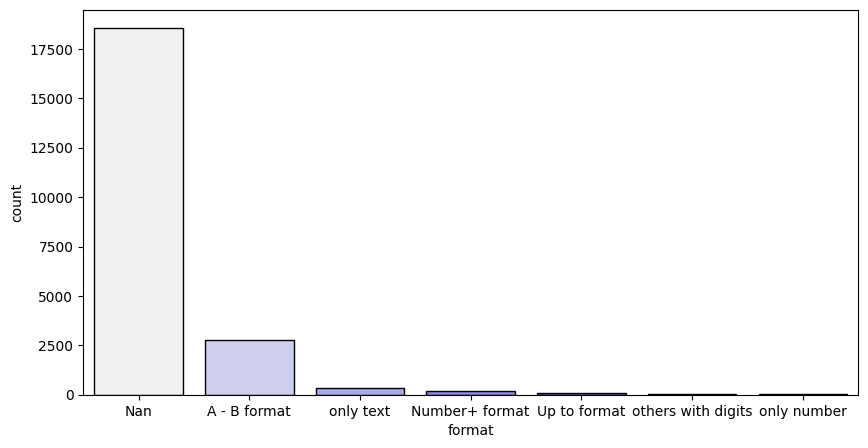

In [ ]:
# построение диаграммы
plt.figure(figsize=(10,5))
sns.barplot(
    data=counts,
    x='format',
    y='count',
    palette="light:b",
    edgecolor='black',
    linewidth=1
)
plt.show()

Так тут пустые значения сильно портят картину, посмотрим без них

/tmp/ipykernel_8045/308566418.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


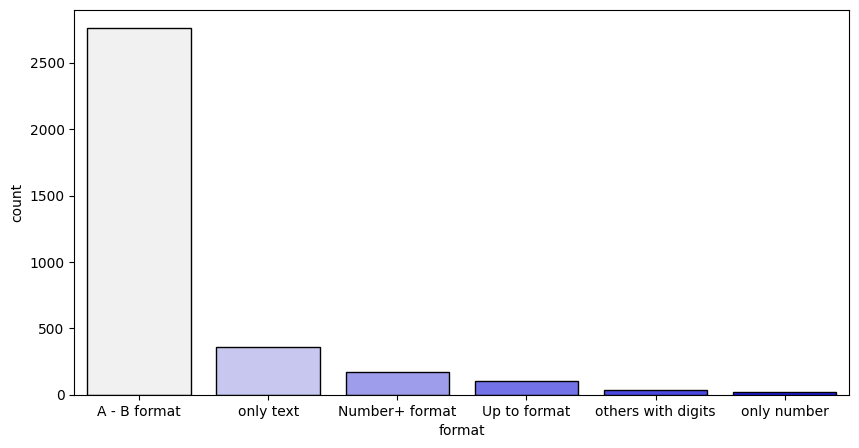

In [ ]:
counts = counts[~counts['format'].isin(['Nan',])]
plt.figure(figsize=(10,5))
sns.barplot(
    data=counts,
    x='format',
    y='count',
    palette="light:b",
    edgecolor='black',
    linewidth=1
)
plt.show()

Итак, чаще всего информации о зарплате нет вообще. Самый популярный формат "A - B", где указана зарплатная вилка.

Тут я не выносил в отдельные группы зарплаты, где по-разному расположен или не расположен знак доллара. Также не делил на то где зарплата указана за какой период (час, год и тд)

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

In [ ]:
def split_salary(s):
  if not isinstance(s, str):
    return pd.Series([None, None, None])
  m = PATTERN.match(s)
  if not m:
    return pd.Series([None, None, None])

  to_num = lambda x: float(x.replace(',','')) if x else None

  low = to_num(m.group('min'))
  high = to_num(m.group('max'))
  if low is None:
    low = to_num(m.group('max_only'))

  period = (m.group('period') or 'no info').lower()
  return pd.Series([low, high, period])

#уберем строки где зарплата пустая, так как они особо данных не дадут
df_s = df_s.dropna(subset='salary')

df_s[['min_salary', 'max_salary', 'period']] = df_s['salary'].apply(split_salary)
df_s[['min_salalry', 'max_salary']] = df_s[['min_salary', 'max_salary']].astype(float)

df_s[['salary', 'min_salary', 'max_salary', 'period']].head(10)



,salary,min_salary,max_salary,period
13,9.00 - 13.00 $ /hour,9.0,13.0,hour
14,"80,000.00 - 95,000.00 $ /year",80000.0,95000.0,year
19,"60,000.00 - 72,000.00 $ /year",60000.0,72000.0,year
23,Excellent Pay and Incentives,NaN,NaN,None
29,"70,000.00 - 100,000.00 $ /year",70000.0,100000.0,year
30,62.00 - 81.00 $ /hour,62.0,81.0,hour
32,"75,000.00 - 100,000.00 $ /year",75000.0,100000.0,year
36,"68,000.00 - 72,000.00 $ /year",68000.0,72000.0,year
41,"58,000.00 - 65,000.00 $ /year",58000.0,65000.0,year
42,Up to $32000.00,32000.0,NaN,no info


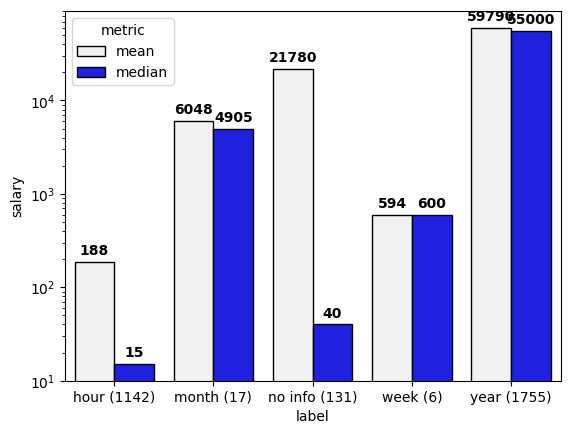

In [ ]:
# построим график
df_for_di = df_s.dropna(subset='min_salary').groupby('period')[
    'min_salary'].agg(mean="mean",median="median",count='count').round(2).reset_index()


df_for_di['label'] = df_for_di['period'] + ' (' + df_for_di['count'].astype(str) +')'
df_for_di = df_for_di.melt(id_vars='label',
                         value_vars=['mean', 'median'],
                         var_name='metric',
                         value_name='salary')

ax = sns.barplot(data=df_for_di,
            x='label',
            y='salary',
            hue='metric',
            palette='light:b',
            edgecolor='black')
ax.set_yscale('log')
for c in ax.containers:
    ax.bar_label(
        c,
        labels=[f'{v:.0f}' for v in c.datavalues],
        padding=3,
        fontsize=10,
        fontweight='bold',
    )

Сравнивать между собой зарплату за час, месяц, год и тд не имеет смысла, так как тут разные размерности.

Из того что можно заметить, что среднее сильно больше медианы у группы hour, то есть в данных есть выбросы.

У групп month и year средне также больше медианы, на несколько тысяч, распределение немного скошено вправо

У недели маленькое различие, практически совпадают.

При этом важно заметить, что у групп month и week очень мало наблюдений, поэтому  выводы по ним делать нельзя.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

In [ ]:
df_s = df_s[['salary', 'min_salary', 'max_salary', 'period']]
df_s = df_s.dropna(subset='min_salary')
df_s['diff'] = df_s['max_salary'] - df_s['min_salary']


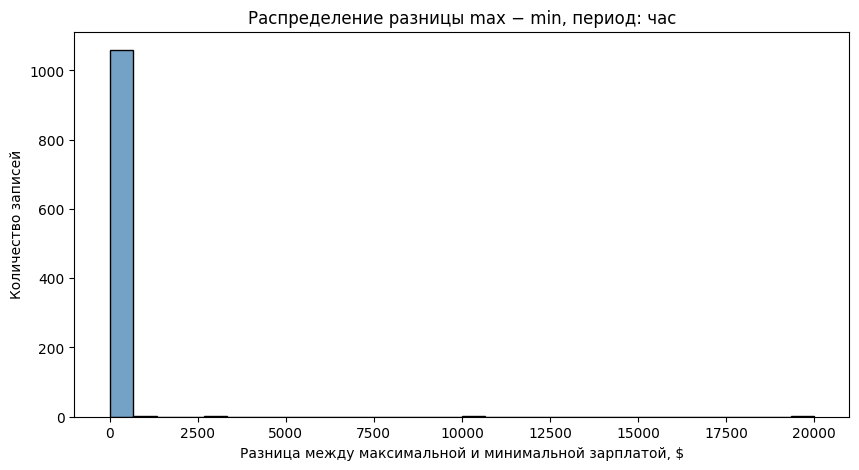

In [ ]:

df_for_d = df_s[df_s['period'] == 'hour']['diff'].dropna()
plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df_for_d, bins=30, color='steelblue', edgecolor='black')
ax.set_title('Распределение разницы max − min, период: час')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $')
ax.set_ylabel('Количество записей')
plt.show()

Очевидно есть выбросы, не очень понятно, что происходит. Обрежем по 99% перцентилю.

In [ ]:
df_d = df_s.loc[df_s['period'] == 'hour', 'diff'].dropna()
print(df_d.describe())
print(df_d.quantile([0.5, 0.9, 0.95, 0.99]))
print(df_s[(df_s['period'] == 'hour') & (df_s['diff'] > 100)][['salary', 'diff']])

count     1063.000000
mean        37.390009
std        691.991822
min          0.000000
25%          1.000000
50%          3.000000
75%          6.390000
max      20000.000000
Name: diff, dtype: float64
0.50     3.0
0.90    13.0
0.95    20.0
0.99    35.0
Name: diff, dtype: float64
                                salary     diff
6891   100,000.00 - 120,000.00 $ /hour  20000.0
7194             9.00 - 900.00 $ /hour    891.0
10298    60,000.00 - 70,000.00 $ /hour  10000.0
12416    32,000.00 - 35,000.00 $ /hour   3000.0
21086           22.47 - 422.47 $ /hour    400.0


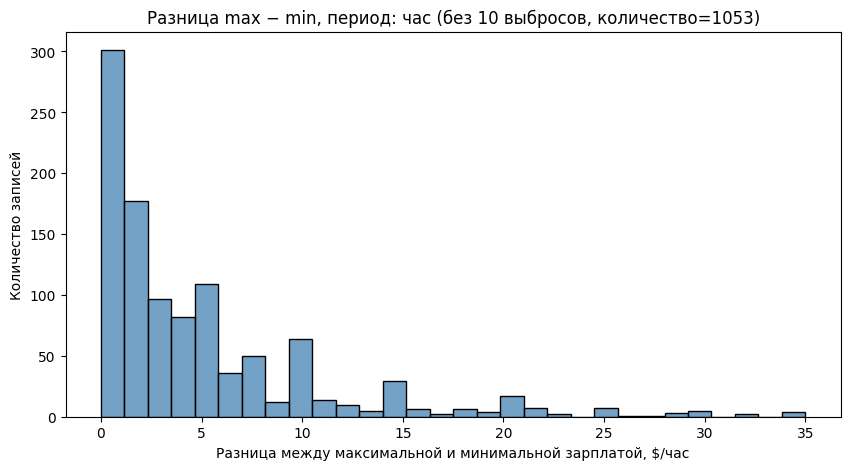

In [ ]:
threshold = df_d.quantile(0.99)
data_trim = df_d[df_d <= threshold]
removed = len(df_d) - len(data_trim)

plt.figure(figsize=(10, 5))
ax = sns.histplot(data=data_trim, bins=30, color='steelblue', edgecolor='black')
ax.set_title(f'Разница max − min, период: час (без {removed} выбросов, количество={len(data_trim)})')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $/час')
ax.set_ylabel('Количество записей')
plt.show()

Фраза про выбросы говорилась в задании 2.2 так что в целом соотносится.

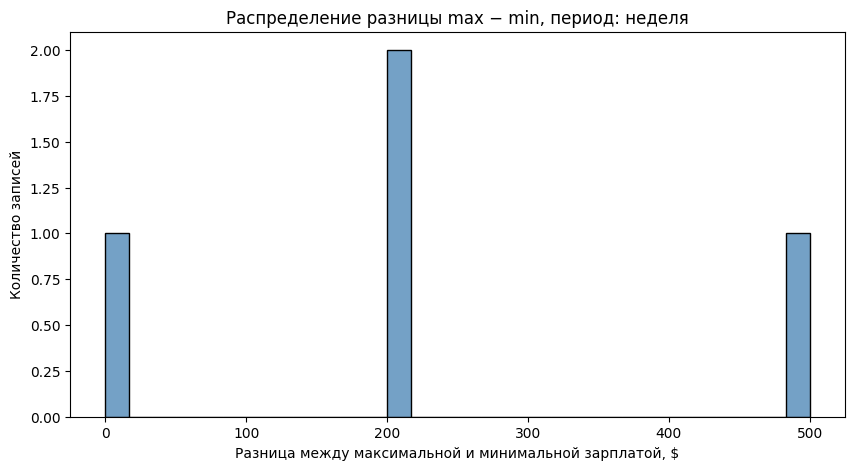

In [ ]:
df_for_d = df_s[df_s['period'] == 'week']['diff'].dropna()
plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df_for_d, bins=30, color='steelblue', edgecolor='black')
ax.set_title('Распределение разницы max − min, период: неделя')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $')
ax.set_ylabel('Количество записей')
plt.show()

Тут все печально, но как говорилось выше данных слишком мало для полноценной работы, всего лишь 6 штук.

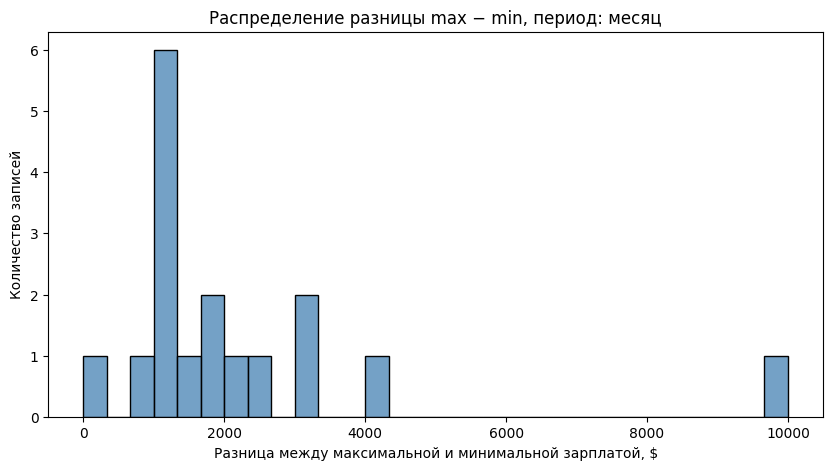

In [ ]:
df_for_d = df_s[df_s['period'] == 'month']['diff'].dropna()
plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df_for_d, bins=30, color='steelblue', edgecolor='black')
ax.set_title('Распределение разницы max − min, период: месяц')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $')
ax.set_ylabel('Количество записей')
plt.show()

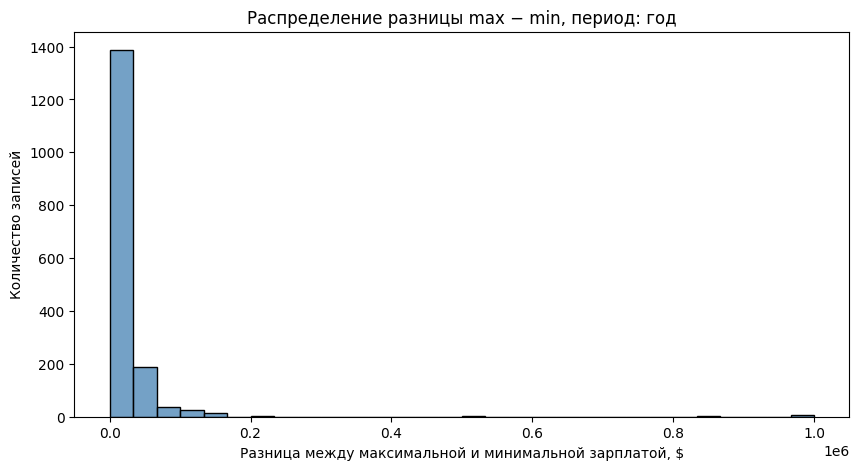

In [ ]:
df_for_d = df_s[df_s['period'] == 'year']['diff'].dropna()
plt.figure(figsize=(10, 5))
ax = sns.histplot(data=df_for_d, bins=30, color='steelblue', edgecolor='black')
ax.set_title('Распределение разницы max − min, период: год')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $')
ax.set_ylabel('Количество записей')
plt.show()

Также выглядит не очень приятно, поправим выбросы

In [ ]:
df_d = df_s.loc[df_s['period'] == 'year', 'diff'].dropna()
print(df_d.describe())
print(df_d.quantile([0.5, 0.9, 0.95, 0.99]))
print(df_s[(df_s['period'] == 'year') & (df_s['diff'] > 100)][['salary', 'diff']])

count      1664.000000
mean      27055.500992
std       78062.150615
min           0.000000
25%        8000.000000
50%       15000.000000
75%       25000.000000
max      999999.000000
Name: diff, dtype: float64
0.50     15000.0
0.90     55000.0
0.95     70000.0
0.99    150000.0
Name: diff, dtype: float64
                                                  salary     diff
14                         80,000.00 - 95,000.00 $ /year  15000.0
19                         60,000.00 - 72,000.00 $ /year  12000.0
29                        70,000.00 - 100,000.00 $ /year  30000.0
32                        75,000.00 - 100,000.00 $ /year  25000.0
36                         68,000.00 - 72,000.00 $ /year   4000.0
...                                                  ...      ...
21976        40,000.00 - 42,000.00 $ /yearProfit-sharing   2000.0
21982                      70,000.00 - 80,000.00 $ /year  10000.0
21995               120,000.00 - 160,000.00 $ /yearbonus  40000.0
21996                      45,000.

Конечно вилка миллион долларов это круто, но не очень реалистично. Убираем

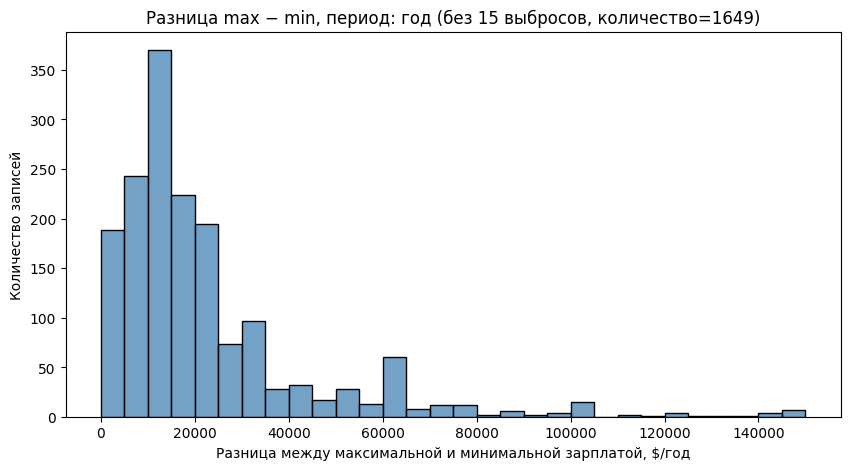

In [ ]:
threshold = df_d.quantile(0.99)
data_trim = df_d[df_d <= threshold]
removed = len(df_d) - len(data_trim)

plt.figure(figsize=(10, 5))
ax = sns.histplot(data=data_trim, bins=30, color='steelblue', edgecolor='black')
ax.set_title(f'Разница max − min, период: год (без {removed} выбросов, количество={len(data_trim)})')
ax.set_xlabel('Разница между максимальной и минимальной зарплатой, $/год')
ax.set_ylabel('Количество записей')
plt.show()

Распределение правда скошено вправо, соотносится с 2.2

In [ ]:
df_f = df_s.dropna(subset='min_salary').groupby('period')[
    'min_salary'].agg(median="median",count='count').round(2).reset_index()
df_f

,period,median,count
0,hour,15.13,1142
1,month,4905.22,17
2,no info,40.00,131
3,week,600.00,6
4,year,55000.00,1755


In [ ]:
def tail(s):
    m = PATTERN.match(s)
    return m.group('extra').strip().lower()[:25] if m else None

df_s['tail'] = df_s['salary'].map(tail)
df_s.loc[df_s['period'] == 'no info', 'tail'].value_counts().head(20)


,count
tail,
,115
hiring bonus,2
sign-on bonus,1
"k, medical, dental",1
/per day + gas,1
bi-weeklypay increase upo,1
per hour,1
k/up starting salary comm,1
"weeks paid vacation, 6 pa",1


Так точно видно есть за час (per hour /hr) , но он не учелся из-за другого формата. Есть за год но в евро, поэтому его тоже особо никуда не прицепишь. За день мы никуда не распределим. Остальные из не пустых  немного шумящие. Пустые надо сверять и смотреть по числам.

In [ ]:

no = df_s['period'] == 'no info'
t = df_s['tail']


df_s.loc[no & t.str.contains(r'hour|/hr'), 'period'] = 'hour'
df_s.loc[no & t.str.contains('year'), 'period'] = 'year'
df_s.loc[no & t.str.contains(r'day|bi-week'), 'period'] = 'other'


df_s.loc[no & t.str.match(r'k|weeks'), 'period'] = 'not a salary'

print(df_s['period'].value_counts())

period
year            1756
hour            1144
no info          119
month             17
week               6
not a salary       5
other              4
Name: count, dtype: int64


In [ ]:
df_s[df_s['period']=='no info'][['min_salary', 'salary']]

,min_salary,salary
42,32000.0,Up to $32000.00
154,45000.0,Up to $45000.00
484,300.0,$300 Hiring Bonus
1067,4000.0,"$4,000 Sign-On Bonus"
2424,108887.0,"108,887.00 - 141,555.00"
...,...,...
19464,1000.0,$1000 HIRING BONUS
20014,14.0,Up to $14.00
21168,20.0,Up to $20.00
21270,31500.0,Up to $31500.00


уберем бонусы это не совсем зарплата

In [ ]:
no = df_s['period'].eq('no info')
t = df_s['tail'].fillna('')

bonus_mask = no & t.str.contains(
    r'bonus',
    case=False,
    regex=True
)

display(df_s.loc[bonus_mask, ['salary', 'tail']])
df_s.loc[no & t.str.contains(r'bonus'), 'period'] = 'other'
df_s['period'].value_counts()


,salary,tail
484,$300 Hiring Bonus,hiring bonus
1067,"$4,000 Sign-On Bonus",sign-on bonus
19464,$1000 HIRING BONUS,hiring bonus


,count
period,
year,1756
hour,1144
no info,116
month,17
other,7
week,6
not a salary,5


примерно раскидаем

In [ ]:
known = df_s[df_s['period'].isin(['hour', 'week', 'month', 'year'])]
ref = known.groupby('period')['min_salary'].median()

def closest(v, tol=0.01):
    d = (ref - v).abs().sort_values()
    if np.isclose(d.iloc[0], d.iloc[1], rtol=tol):
        return None
    return d.index[0]

mask = df_s['period'] == 'no info'
df_s.loc[mask, 'guessed_period'] = df_s.loc[mask, 'min_salary'].map(closest)
df_s['guessed_period'].value_counts()

,count
guessed_period,
hour,66
year,47
month,1


посмотрим что получилось

In [ ]:
df_s[df_s['guessed_period'] == 'year'].head(10)

,salary,min_salary,max_salary,period,diff,tail,guessed_period
42,Up to $32000.00,32000.0,NaN,no info,NaN,,year
154,Up to $45000.00,45000.0,NaN,no info,NaN,,year
2424,"108,887.00 - 141,555.00",108887.0,141555.0,no info,32668.0,,year
3102,Up to $31000.00,31000.0,NaN,no info,NaN,,year
3165,Up to $150000.00,150000.0,NaN,no info,NaN,,year
3251,Up to $92000.00,92000.0,NaN,no info,NaN,,year
3711,Up to $92000.00,92000.0,NaN,no info,NaN,,year
4251,Up to $60000.00,60000.0,NaN,no info,NaN,,year
5249,Up to $35000.00,35000.0,NaN,no info,NaN,,year
5314,Up to $60000.00,60000.0,NaN,no info,NaN,,year


Получаеся похожее на правду.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

In [ ]:
jt = df['job_type'].astype(str).str.strip()
print(f"Всего строк: {len(df)}")
print(f'Пустых (NaNских бедолаг): {df["job_type"].isna().sum()}')
print(f"Уникальных значений: {jt.nunique()}")

Всего строк: 22000
Пустых (NaNских бедолаг): 1628
Уникальных значений: 38


In [ ]:
display(jt.value_counts().head(38).to_frame('count'))

,count
job_type,
Full Time,6771
Full Time Employee,6617
"Full Time, Employee",3360
nan,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,330


Тут мы увидели, что есть 38 уникальных значений. Мы по таблице видим, какие значения являются самыми частыми, но тут какая-то беда, что буквально Full Time Employee и Full Time, Employee значат одно и то же. Сейчас будем с этим работать

Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [ ]:
def normalize(val):
    if pd.isna(val):
        return None
    s = str(val).strip()
    if s.lower() in ('nan', ''):
        return None
    s = re.sub(r'^job\s*type\s*[:\-–]?\s*', '', s, flags=re.IGNORECASE).strip()
    s = re.sub(r'[<>]', '', s)
    s = re.sub(r'\s*[,/]\s*', ' ', s)
    s = re.sub(r'\s+-\s+', ' ', s)
    s = re.sub(r'\s+', ' ', s)
    s = s.strip(' ,;-–')
    s = s.title()
    replacements = {
        'Fulltime':                          'Full Time',
        'Parttime':                          'Part Time',
        'Contract':                          'Contractor',
        'Temp':                              'Temporary',
        'Temporary Employee':                'Temporary',
        'Temporary/Contract/Project':        'Temporary/Contract/Project',
    }
    for k, v in replacements.items():
        if s.lower() == k.lower():
            return v
    return s
df['job_type_clean'] = df['job_type'].apply(normalize)

print("уникальных значений (без NaN):", df['job_type_clean'].dropna().nunique())
print("\nРаспределение очищенных значений:")
display(df['job_type_clean'].value_counts())

уникальных значений (без NaN): 15

Распределение очищенных значений:


,count
job_type_clean,
Full Time Employee,10538
Full Time,6773
Full Time Temporary Contract Project,1654
Part Time Employee,586
Part Time,330
Temporary Contract Project,193
Employee,148
Part Time Temporary Contract Project,57
Per Diem Employee,41


Выглядит уже хайповее. По крайней мере, я  не вижу повторяющихся признаков. Можно попробовать визуализировать (до этого я не хотел этого делать, так как значений было очень много и они совпадали даже в самых частых).

P.S. начал делать след задание и заметил реально то что у нас есть кол-во занятости и тип занятости. Построим график и потом исправим

/tmp/ipykernel_8045/2858163915.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=vc, y='job_type', x='count', palette='light:coral',


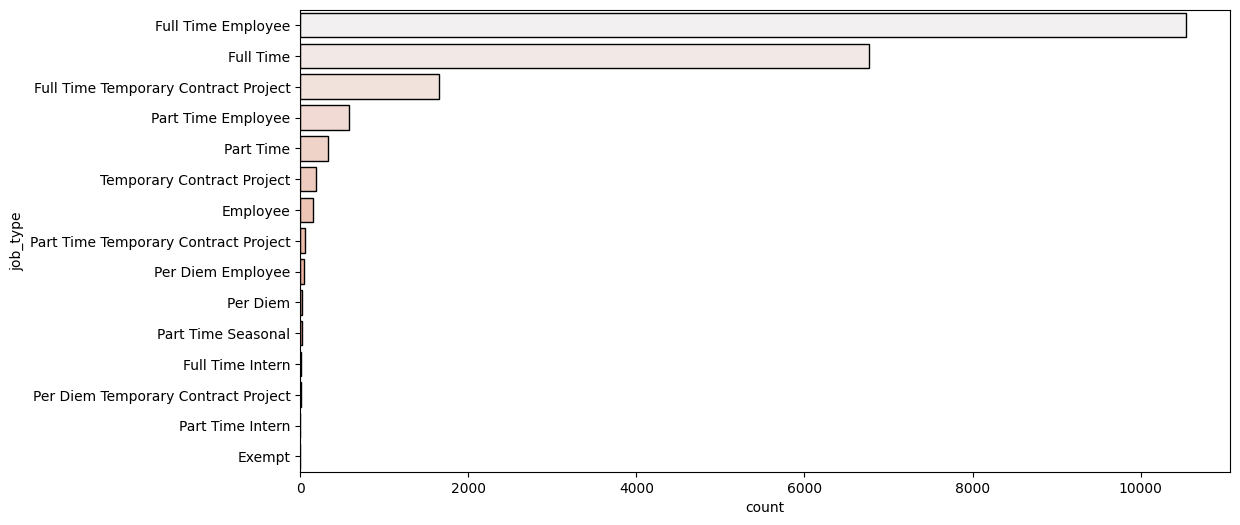

In [ ]:
plt.figure(figsize=(12, 6))
vc = df['job_type_clean'].value_counts().reset_index()
vc.columns = ['job_type', 'count']
sns.barplot(data=vc, y='job_type', x='count', palette='light:coral',
            edgecolor='black', linewidth=1)
plt.show()

Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

In [ ]:
FULLNESS_PATTERNS = [
    (r'\bFull\s*Time\b',       'Full Time'),
    (r'\bPart\s*Time\b',       'Part Time'),
    (r'\bPer\s*Diem\b',        'Per Diem'),
    (r'\bTemporary\b|\bTemp\b','Temporary'),
    (r'\bContract(?:or)?\b',   'Contractor'),
    (r'\bFreelance\b',         'Freelance'),
    (r'\bIntern(?:ship)?\b',   'Intern'),
]
TYPE_PATTERNS = [
    (r'\bEmployee\b',          'Employee'),
    (r'\bIntern(?:ship)?\b',   'Intern'),
    (r'\bContract(?:or)?\b',   'Contractor'),
    (r'\bTemporary\b|\bTemp\b','Temporary'),
    (r'\bFreelance\b',         'Freelance'),
]
def efullness(s):
    if pd.isna(s) or not isinstance(s, str):
        return 'Full Time'
    for rx, label in FULLNESS_PATTERNS:
        if re.search(rx, s, flags=re.IGNORECASE):
            return label
    return 'Full Time'
def etype(s):
    if pd.isna(s) or not isinstance(s, str):
        return 'Employee'
    for rx, label in TYPE_PATTERNS:
        if re.search(rx, s, flags=re.IGNORECASE):
            return label
    return 'Employee'
df['fullness'] = df['job_type_clean'].apply(efullness)
df['type']     = df['job_type_clean'].apply(etype)
display(df['fullness'].value_counts())
display(df['type'].value_counts())

,count
fullness,
Full Time,20747
Part Time,993
Temporary,193
Per Diem,67


,count
type,
Employee,20084
Contractor,1908
Intern,8


Тбалица сопряженности

In [ ]:
cross = pd.crosstab(df['fullness'], df['type'])
cross

type,Contractor,Employee,Intern
fullness,,,
Full Time,1654,19088,5
Part Time,57,933,3
Per Diem,4,63,0
Temporary,193,0,0


Строим столбчатую диаграмму

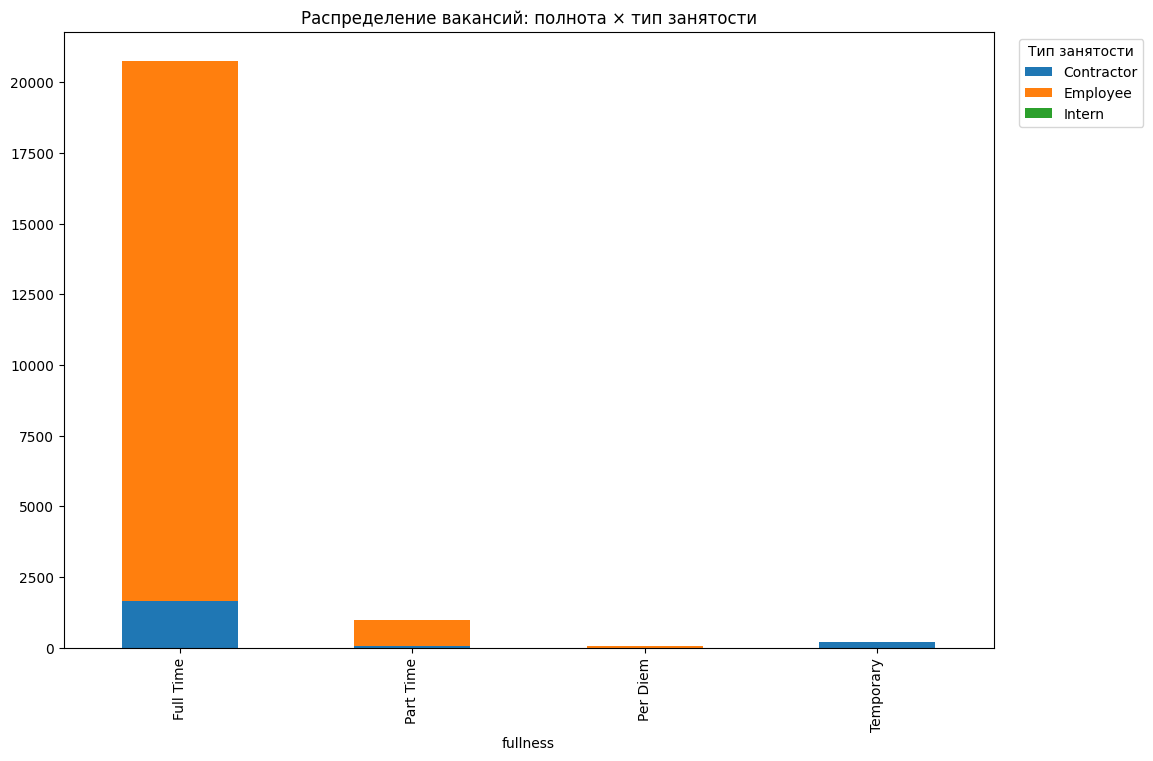

In [ ]:
ax = cross.plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Распределение вакансий: полнота × тип занятости')
plt.legend(title='Тип занятости', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

Как вывод можно сказать, что подавляющее большинство вакансий — Full Time Employee. Part Time. Можно сказать, что большинство записей в датасете это штатные сотрудники - офисные планктоны

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.